# Assignment 6 — MLP for Heart Disease Prediction

**Dataset:** [Heart Disease (Cleveland)](https://archive.ics.uci.edu/dataset/45/heart+disease), UCI Machine Learning Repository. 303 patients with 13 clinical attributes and a diagnosis of angiographic coronary artery disease.
**Task:** binary classification, **heart disease present (1) vs absent (0)**, comparing two Multi-Layer Perceptron architectures built with TensorFlow/Keras.

| Requirement | Section |
|---|---|
| Preprocess and split the dataset appropriately | 1–2 |
| Design two MLP architectures with different hidden-layer configurations | 3 |
| Train and evaluate both networks | 4–5 |
| Compare Accuracy, Precision, Recall and F1 Score | 5–6 |
| Conclude which architecture performs better and justify the decision | 7 |

## 0. Setup

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import time
import urllib.request
import zipfile
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
tf.get_logger().setLevel("ERROR")
DATA_DIR, FIG_DIR, RES_DIR = Path("data"), Path("figures"), Path("results")
for d in (DATA_DIR, FIG_DIR, RES_DIR):
    d.mkdir(exist_ok=True)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.15.1


In [2]:
# Plot style: one consistent, colour-blind-checked palette for every figure
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.labelsize": 10, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.prop_cycle": cycler(color=PALETTE), "lines.linewidth": 2, "lines.markersize": 6,
    "legend.frameon": False, "text.color": INK, "figure.dpi": 110, "savefig.dpi": 150,
    "savefig.bbox": "tight", "font.size": 10,
})
ARCH_COLORS = {"MLP-A (compact)": PALETTE[0], "MLP-B (deep & wide)": PALETTE[1]}

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

## 1. Load and understand the data

I use the processed Cleveland file. It is the subset used in almost all published work on this dataset, and the only one of the four UCI sites with complete clinical attributes. Missing values are coded as `"?"`.

| Feature | Meaning | Type |
|---|---|---|
| `age` | age in years | numeric |
| `sex` | 1 = male, 0 = female | binary |
| `cp` | chest pain type (1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic) | nominal |
| `trestbps` | resting blood pressure (mm Hg) | numeric |
| `chol` | serum cholesterol (mg/dl) | numeric |
| `fbs` | fasting blood sugar > 120 mg/dl | binary |
| `restecg` | resting ECG (0 normal, 1 ST-T abnormality, 2 left-ventricular hypertrophy) | nominal |
| `thalach` | maximum heart rate achieved | numeric |
| `exang` | exercise-induced angina | binary |
| `oldpeak` | ST depression induced by exercise relative to rest | numeric |
| `slope` | slope of the peak exercise ST segment (1 up, 2 flat, 3 down) | nominal |
| `ca` | number of major vessels (0–3) coloured by fluoroscopy | numeric (count) |
| `thal` | thallium stress test (3 normal, 6 fixed defect, 7 reversible defect) | nominal |
| `num` | diagnosis: 0 = no disease, 1–4 = increasing severity | **target** |

In [3]:
COLS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang",
        "oldpeak", "slope", "ca", "thal", "num"]
path = DATA_DIR / "processed.cleveland.data"
if not path.exists():
    urllib.request.urlretrieve("https://archive.ics.uci.edu/static/public/45/heart+disease.zip", DATA_DIR / "hd.zip")
    zipfile.ZipFile(DATA_DIR / "hd.zip").extract("processed.cleveland.data", DATA_DIR)

df = pd.read_csv(path, header=None, names=COLS, na_values="?")
print("shape:", df.shape, "| duplicate rows:", df.duplicated().sum())
print("missing values:", df.isna().sum()[df.isna().sum() > 0].to_dict())
print("diagnosis (num) distribution:", df["num"].value_counts().sort_index().to_dict())
df.head()

shape: (303, 14) | duplicate rows: 0
missing values: {'ca': 4, 'thal': 2}
diagnosis (num) distribution: {0: 164, 1: 55, 2: 36, 3: 35, 4: 13}


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


* **Target:** `num` grades severity from 0 to 4. Grades 1–4 have only 13–55 patients each, too few to learn five classes reliably. Following the standard practice for this dataset, I predict **presence (num ≥ 1) vs absence (num = 0)** of heart disease, which gives two nearly balanced classes.
* **Missing values:** only 6 values are missing (4 in `ca`, 2 in `thal`). Dropping those rows would lose 2% of an already tiny dataset, so I **impute** them inside the preprocessing pipeline: median for numeric and most frequent value for categorical. The imputers learn from the training data only.

class balance: {'no disease': 164, 'disease': 139}


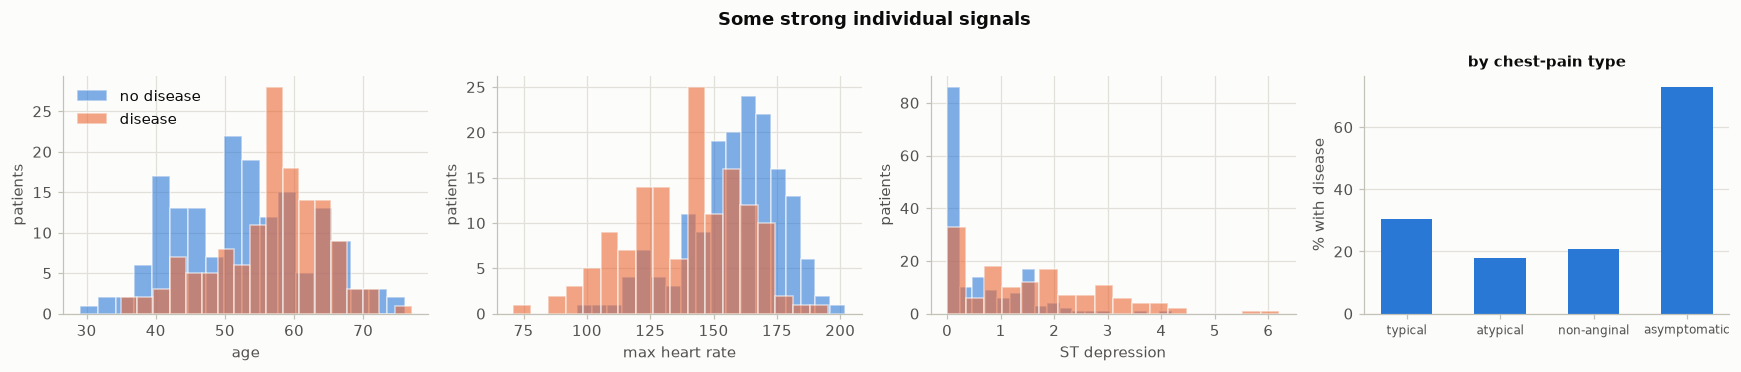

In [4]:
df["target"] = (df["num"] > 0).astype(int)
df = df.drop(columns="num")
print("class balance:", df["target"].map({0: "no disease", 1: "disease"}).value_counts().to_dict())

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, col, xl in [(axes[0], "age", "age"), (axes[1], "thalach", "max heart rate"), (axes[2], "oldpeak", "ST depression")]:
    for v, c, lbl in [(0, PALETTE[0], "no disease"), (1, PALETTE[1], "disease")]:
        ax.hist(df.loc[df.target == v, col], bins=18, color=c, alpha=0.6, label=lbl, edgecolor=SURFACE)
    ax.set_xlabel(xl); ax.set_ylabel("patients")
axes[0].legend(loc="upper left")
rate = df.groupby("cp")["target"].mean() * 100
axes[3].bar(["typical", "atypical", "non-anginal", "asymptomatic"], rate.values, color=PALETTE[0], width=0.55)
axes[3].set_ylabel("% with disease"); axes[3].set_title("by chest-pain type", fontsize=10); axes[3].grid(axis="x", visible=False)
axes[3].tick_params(axis="x", labelsize=8)
fig.suptitle("Some strong individual signals", fontweight="bold", color=INK)
fig.tight_layout(); save(fig, "01_eda")

Patients with disease tend to be older, reach a **lower maximum heart rate**, and show more **ST depression**. Counter-intuitively, **asymptomatic** chest pain is the type most associated with disease. This well-known quirk of the dataset shows why chest-pain type must be **one-hot encoded** as a category and not treated as a number.

## 2. Split and preprocess

**Split (stratified):** 20% held-out **test** set (61 patients). The remaining 80% is split again into **train** (64% of the total) and **validation** (16%). The validation set is used for early stopping, and the test set only for the final evaluation.

**Preprocessing (`ColumnTransformer`, fitted on the training set only):**
* numeric (`age, trestbps, chol, thalach, oldpeak, ca`): median imputation → `StandardScaler`. Neural networks train much better with zero-mean, unit-variance inputs, because the gradients for all weights are then on a comparable scale;
* nominal (`cp, restecg, slope, thal`): most-frequent imputation → **one-hot encoding**, so the network does not assume that "asymptomatic (4)" is twice "atypical (2)". The category lists are fixed from the data dictionary, so every split produces the same 22 inputs even when a rare level (e.g. `restecg = 1`, only 4 patients) happens to be absent from a training fold;
* binary (`sex, fbs, exang`): already 0/1, so they pass through unchanged.

In [5]:
NUMERIC = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
NOMINAL = ["cp", "restecg", "slope", "thal"]
CATEGORIES = [[1.0, 2.0, 3.0, 4.0], [0.0, 1.0, 2.0], [1.0, 2.0, 3.0], [3.0, 6.0, 7.0]]   # from heart-disease.names
BINARY = ["sex", "fbs", "exang"]

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUMERIC),
        ("nom", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(categories=CATEGORIES, handle_unknown="ignore", sparse_output=False))]), NOMINAL),
        ("bin", SimpleImputer(strategy="most_frequent"), BINARY),
    ], verbose_feature_names_out=False)

X, y = df.drop(columns="target"), df["target"].values
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.20, stratify=y_dev, random_state=SEED)

prep = make_preprocessor().fit(X_train)
Xtr, Xva, Xte = (prep.transform(d).astype("float32") for d in (X_train, X_val, X_test))
ytr, yva, yte = (v.astype("float32") for v in (y_train, y_val, y_test))
N_FEATURES = Xtr.shape[1]
for name, yy in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:10s}: {len(yy):3d} patients, {yy.mean():.1%} with disease")
print(f"\n13 raw attributes → {N_FEATURES} network inputs:", list(prep.get_feature_names_out()))

train     : 193 patients, 46.1% with disease
validation:  49 patients, 44.9% with disease
test      :  61 patients, 45.9% with disease

13 raw attributes → 22 network inputs: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca', 'cp_1.0', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'restecg_0.0', 'restecg_1.0', 'restecg_2.0', 'slope_1.0', 'slope_2.0', 'slope_3.0', 'thal_3.0', 'thal_6.0', 'thal_7.0', 'sex', 'fbs', 'exang']


## 3. Two MLP architectures

Both networks get the same 22 inputs and the same output layer, a single **sigmoid** neuron giving P(disease). They differ **only in their hidden layers**:

| | **MLP-A: compact** | **MLP-B: deep & wide** |
|---|---|---|
| Hidden layers | 2 | 3 |
| Neurons per hidden layer | 16 → 8 | 128 → 64 → 32 |
| Hidden activation | ReLU | ReLU |
| Dropout after each hidden layer | 0.2 | 0.2 |
| Trainable parameters | about 0.5 k | about 13 k |
| Design idea | capacity matched to a small tabular dataset | much more capacity: can it find more complex patterns? |

**Everything else is identical**, so any difference in results comes from the hidden-layer configuration: ReLU hidden activations, He-normal initialisation, dropout 0.2, Adam (lr = 0.001), binary cross-entropy, batch size 16, at most 300 epochs with **early stopping** (patience 30, restore the weights from the epoch with the lowest validation loss).

* **ReLU** in the hidden layers adds the non-linearity that lets an MLP learn curved decision boundaries. That is the key difference from a single-layer perceptron.
* **Dropout** randomly switches off 20% of the hidden neurons at each training step. This stops neurons from co-adapting and reduces overfitting.

In [6]:
ARCHS = {"MLP-A (compact)": [16, 8], "MLP-B (deep & wide)": [128, 64, 32]}

def build_mlp(hidden_units, dropout=0.2, name="mlp"):
    layers = [keras.Input(shape=(N_FEATURES,), name="clinical_features")]
    for i, units in enumerate(hidden_units, start=1):
        layers += [keras.layers.Dense(units, activation="relu", kernel_initializer="he_normal", name=f"hidden_{i}"),
                   keras.layers.Dropout(dropout, name=f"dropout_{i}")]
    layers.append(keras.layers.Dense(1, activation="sigmoid", name="p_disease"))
    model = keras.Sequential(layers, name=name)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")])
    return model

def train(model, X_tr, y_tr, X_va, y_va, epochs=300, patience=30, verbose=0):
    cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)] if patience else []
    t0 = time.perf_counter()
    h = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=epochs, batch_size=16, callbacks=cb, verbose=verbose)
    return pd.DataFrame(h.history, index=pd.RangeIndex(1, len(h.history["loss"]) + 1, name="epoch")), time.perf_counter() - t0

for arch, hidden in ARCHS.items():
    keras.utils.set_random_seed(SEED)
    build_mlp(hidden, name=arch.split(" ")[0].replace("-", "_")).summary()

Model: "MLP_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 16)             │           368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_disease (Dense)               │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

Model: "MLP_B"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 128)            │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_3 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_disease (Dense)               │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,313 (52.00 KB)

 Trainable params: 13,313 (52.00 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Train both networks

### 4.1 Learning behaviour without early stopping

First, both networks are trained for a fixed 300 epochs with no early stopping, to see how each architecture behaves when allowed to train for as long as it likes:

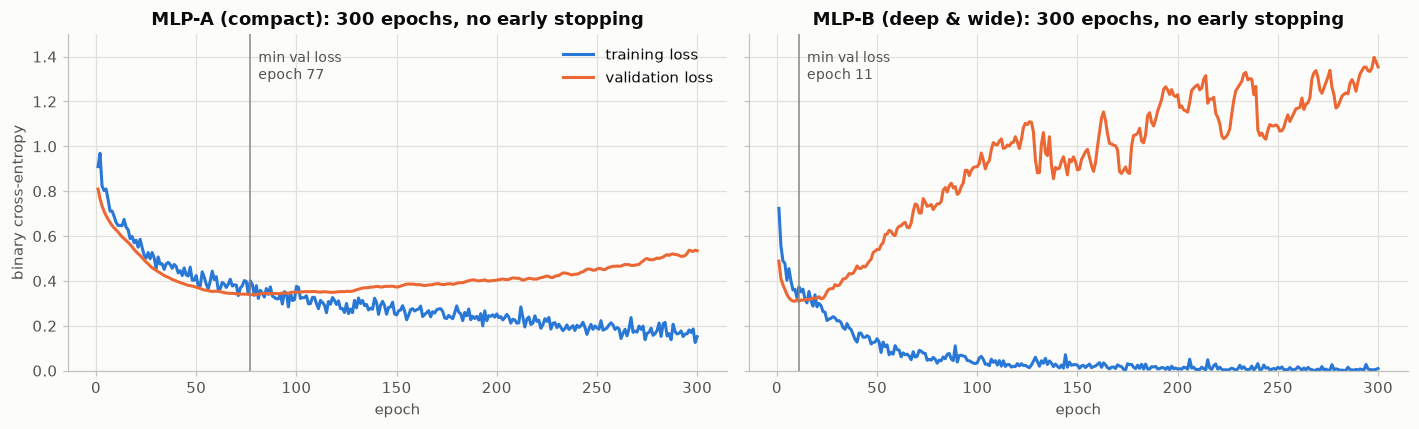

MLP-A (compact)      best val loss 0.338 at epoch  77 | val loss at epoch 300: 0.534 | train loss at 300: 0.151
MLP-B (deep & wide)  best val loss 0.308 at epoch  11 | val loss at epoch 300: 1.354 | train loss at 300: 0.009


In [7]:
free_runs = {}
for arch, hidden in ARCHS.items():
    keras.utils.set_random_seed(SEED)
    free_runs[arch], _ = train(build_mlp(hidden), Xtr, ytr, Xva, yva, epochs=300, patience=None)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (arch, h) in zip(axes, free_runs.items()):
    ax.plot(h.index, h["loss"], color=PALETTE[0], label="training loss")
    ax.plot(h.index, h["val_loss"], color=PALETTE[1], label="validation loss")
    best = h["val_loss"].idxmin()
    ax.axvline(best, color=MUTED, lw=1)
    ax.text(best + 4, 1.3, f"min val loss\nepoch {best}", color=INK2, fontsize=9)
    ax.set_title(f"{arch}: 300 epochs, no early stopping"); ax.set_xlabel("epoch")
axes[0].set_ylabel("binary cross-entropy"); axes[0].legend(loc="upper right"); axes[0].set_ylim(0, 1.5)
fig.tight_layout(); save(fig, "02_free_training_overfitting")
for arch, h in free_runs.items():
    print(f"{arch:20s} best val loss {h['val_loss'].min():.3f} at epoch {h['val_loss'].idxmin():3d} | "
          f"val loss at epoch 300: {h['val_loss'].iloc[-1]:.3f} | train loss at 300: {h['loss'].iloc[-1]:.3f}")

Both networks eventually overfit when they are allowed to train indefinitely: training loss keeps falling while validation loss turns upward. The **deep & wide MLP-B overfits much faster and much more severely**:
* its validation loss bottoms out after only **11 epochs** and then climbs to about **1.35** by epoch 300, while its training loss approaches **0.009**. With about 13 k parameters for 193 training patients, it simply **memorises** the training set;
* the compact MLP-A learns more slowly (best epoch 77) and degrades gently (0.34 → 0.53).

This is why both final models are trained with **early stopping**, which halts training once validation loss stops improving and restores the best weights. It also matters for the final verdict: MLP-B only has a narrow window of about 10 good epochs, while MLP-A's optimum is broad and forgiving.

### 4.2 Final training with early stopping

In [8]:
models, histories, train_info = {}, {}, {}
for arch, hidden in ARCHS.items():
    keras.utils.set_random_seed(SEED)
    m = build_mlp(hidden, name=arch.split(" ")[0].replace("-", "_"))
    h, secs = train(m, Xtr, ytr, Xva, yva)
    models[arch], histories[arch] = m, h
    train_info[arch] = {"trainable params": m.count_params(), "epochs run": len(h),
                        "best epoch": int(h["val_loss"].idxmin()), "train time (s)": round(secs, 1)}
pd.DataFrame(train_info).T.astype({"trainable params": int, "epochs run": int, "best epoch": int})

,trainable params,epochs run,best epoch,train time (s)
MLP-A (compact),513,107,77,2.9
MLP-B (deep & wide),13313,41,11,1.3


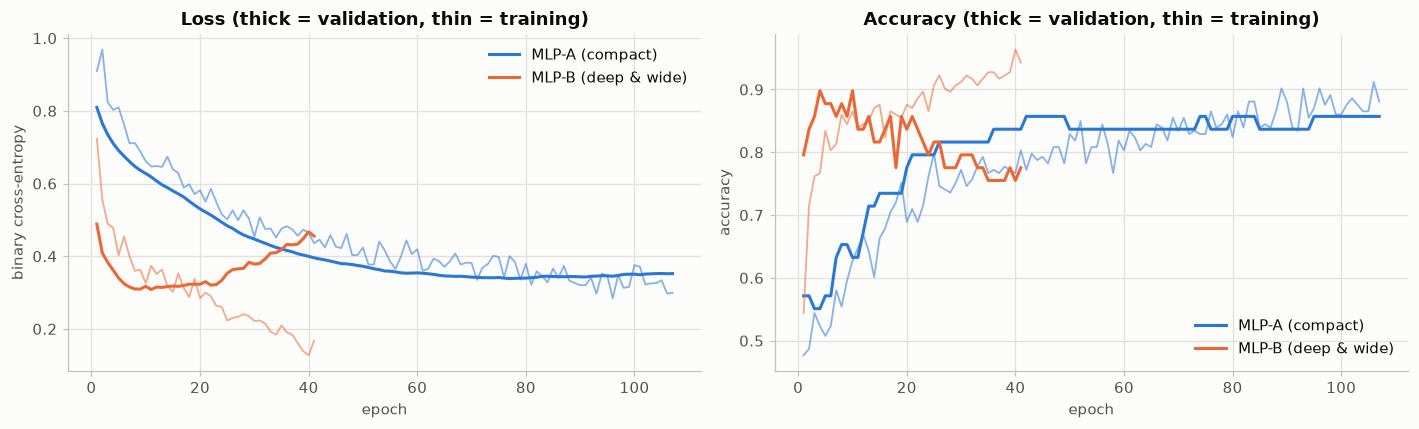

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for arch, h in histories.items():
    c = ARCH_COLORS[arch]
    axes[0].plot(h.index, h["loss"], color=c, lw=1.2, alpha=0.55)
    axes[0].plot(h.index, h["val_loss"], color=c, label=arch)
    axes[1].plot(h.index, h["accuracy"], color=c, lw=1.2, alpha=0.55)
    axes[1].plot(h.index, h["val_accuracy"], color=c, label=arch)
axes[0].set_title("Loss (thick = validation, thin = training)"); axes[0].set_ylabel("binary cross-entropy")
axes[1].set_title("Accuracy (thick = validation, thin = training)"); axes[1].set_ylabel("accuracy")
for ax in axes:
    ax.set_xlabel("epoch"); ax.legend(loc="best")
fig.tight_layout(); save(fig, "03_training_curves_early_stopping")

## 5. Evaluate both networks on the held-out test set

The four required metrics, with **positive = heart disease**:
* **Accuracy**: share of all patients classified correctly.
* **Precision**: of the patients the model flags as diseased, the share who really are. Low precision means unnecessary follow-up tests.
* **Recall (sensitivity)**: of the patients who really have the disease, the share the model catches. Low recall means **missed diagnoses**, the most dangerous error in screening.
* **F1 score**: harmonic mean of precision and recall.

Specificity (recall on healthy patients) and ROC-AUC are added for context.

In [10]:
def scores(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred), "F1": f1_score(y_true, pred),
            "Specificity": tn / (tn + fp), "ROC-AUC": roc_auc_score(y_true, proba)}

test_proba = {arch: m.predict(Xte, verbose=0).ravel() for arch, m in models.items()}
test_table = pd.DataFrame({arch: scores(y_test, p) for arch, p in test_proba.items()}).T
test_table.to_csv(RES_DIR / "test_metrics.csv")
test_table.round(4)

,Accuracy,Precision,Recall,F1,Specificity,ROC-AUC
MLP-A (compact),0.8852,0.8621,0.8929,0.8772,0.8788,0.9524
MLP-B (deep & wide),0.8689,0.8125,0.9286,0.8667,0.8182,0.9535


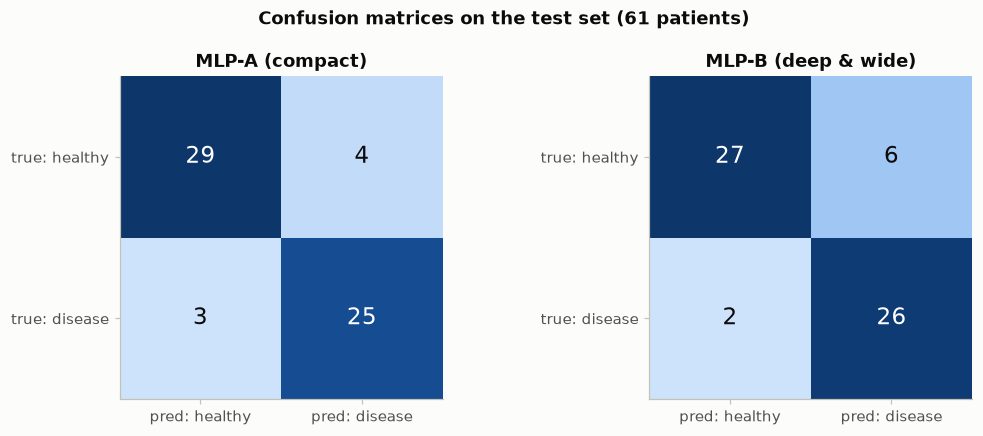

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (arch, p) in zip(axes, test_proba.items()):
    cm = confusion_matrix(y_test, p >= 0.5)
    ax.imshow(cm, cmap=BLUES)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, str(v), ha="center", va="center", fontsize=15, color="white" if v > cm.max() * 0.5 else INK)
    ax.set_xticks([0, 1], ["pred: healthy", "pred: disease"]); ax.set_yticks([0, 1], ["true: healthy", "true: disease"])
    ax.grid(False); ax.set_title(arch)
fig.suptitle(f"Confusion matrices on the test set ({len(y_test)} patients)", fontweight="bold", color=INK)
fig.tight_layout(); save(fig, "04_test_confusion_matrices")

## 6. Is the difference real? Repeated cross-validation

A 61-patient test set is small: a single patient changes accuracy by 1.6 points. One split cannot reliably separate two good models. To get a trustworthy comparison, I repeat the whole procedure (preprocessing fitted on training folds, early stopping on an inner validation split) under **5-fold × 5-repeat stratified cross-validation** on the 242 development patients. That gives **25 paired results per architecture**, because both networks see exactly the same folds. The test set stays untouched.

In [12]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
cv_rows = []
t0 = time.perf_counter()
for fold, (tr_idx, va_idx) in enumerate(rcv.split(X_dev, y_dev)):
    Xa, Xb, ya, yb = X_dev.iloc[tr_idx], X_dev.iloc[va_idx], y_dev[tr_idx], y_dev[va_idx]
    Xa_in, Xa_es, ya_in, ya_es = train_test_split(Xa, ya, test_size=0.2, stratify=ya, random_state=fold)
    p = make_preprocessor().fit(Xa_in)
    A_in, A_es, B = (p.transform(d).astype("float32") for d in (Xa_in, Xa_es, Xb))
    for arch, hidden in ARCHS.items():
        keras.utils.set_random_seed(SEED + fold)
        m = build_mlp(hidden)
        h, secs = train(m, A_in, ya_in.astype("float32"), A_es, ya_es.astype("float32"))
        cv_rows.append({"fold": fold, "arch": arch, **scores(yb, m(B, training=False).numpy().ravel()),
                        "epochs": len(h), "seconds": secs})
cv = pd.DataFrame(cv_rows)
cv.to_csv(RES_DIR / "repeated_cv_fold_scores.csv", index=False)
print(f"25 folds × 2 architectures trained in {time.perf_counter() - t0:.0f}s")

METRICS = ["Accuracy", "Precision", "Recall", "F1", "Specificity", "ROC-AUC"]
cv_summary = cv.groupby("arch")[METRICS].agg(["mean", "std"]).round(4)
cv_summary

25 folds × 2 architectures trained in 669s


Accuracy         Precision          Recall          \
                        mean     std      mean     std    mean     std   
arch                                                                     
MLP-A (compact)       0.8090  0.0599    0.8225  0.0937  0.7564  0.0735   
MLP-B (deep & wide)   0.8056  0.0596    0.8135  0.0940  0.7618  0.0830   

                         F1         Specificity         ROC-AUC          
                       mean     std        mean     std    mean     std  
arch                                                                     
MLP-A (compact)      0.7845  0.0637      0.8533  0.0905  0.8762  0.0447  
MLP-B (deep & wide)  0.7823  0.0652      0.8424  0.0946  0.8812  0.0519

In [13]:
paired = []
for metric in METRICS:
    a = cv[cv.arch == "MLP-A (compact)"].set_index("fold")[metric]
    b = cv[cv.arch == "MLP-B (deep & wide)"].set_index("fold")[metric]
    d = a - b
    w = stats.wilcoxon(a, b, zero_method="zsplit").pvalue if (d != 0).any() else 1.0
    paired.append({"metric": metric, "A mean": a.mean(), "B mean": b.mean(), "mean diff (A − B)": d.mean(),
                   "A better (folds)": int((d > 0).sum()), "B better (folds)": int((d < 0).sum()),
                   "ties": int((d == 0).sum()), "Wilcoxon p": w})
paired = pd.DataFrame(paired).set_index("metric")
paired.to_csv(RES_DIR / "paired_comparison.csv")
paired.round(4)

,A mean,B mean,mean diff (A − B),A better (folds),B better (folds),ties,Wilcoxon p
metric,,,,,,,
Accuracy,0.8090,0.8056,0.0034,11,11,3,0.9249
Precision,0.8225,0.8135,0.0090,12,10,3,0.7775
Recall,0.7564,0.7618,-0.0055,5,6,14,0.7002
F1,0.7845,0.7823,0.0022,11,11,3,0.9464
Specificity,0.8533,0.8424,0.0109,9,9,7,0.8290
ROC-AUC,0.8762,0.8812,-0.0050,11,14,0,0.3674


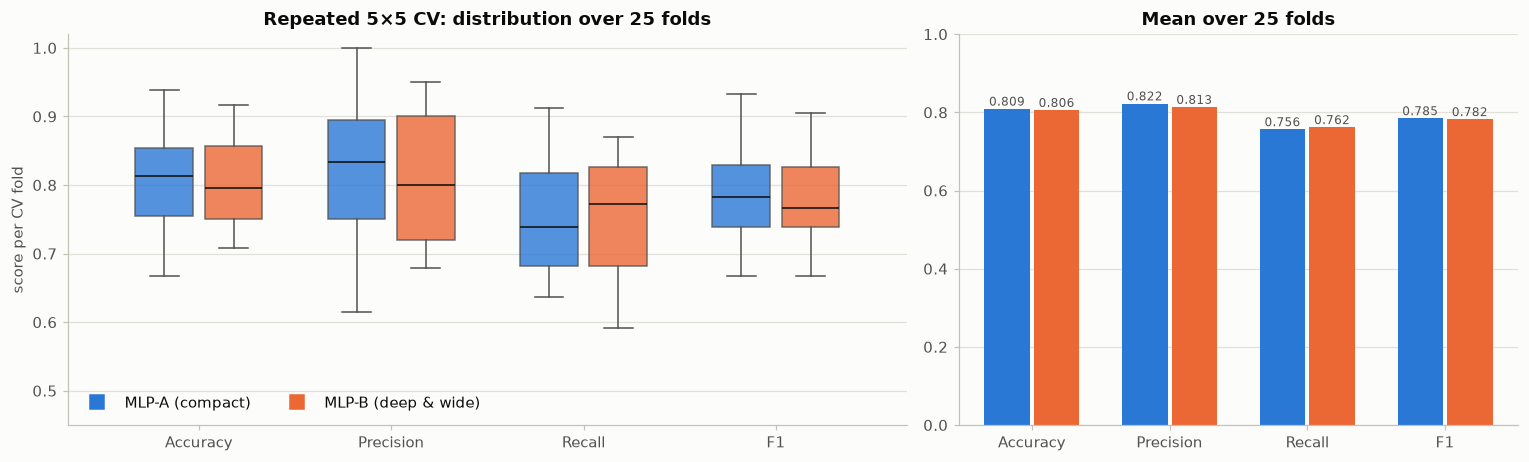

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [1.5, 1]})
four = ["Accuracy", "Precision", "Recall", "F1"]
pos = np.arange(len(four))
for k, arch in enumerate(ARCHS):
    data = [cv.loc[cv.arch == arch, m].values for m in four]
    bp = axes[0].boxplot(data, positions=pos + (k - 0.5) * 0.36, widths=0.3, patch_artist=True,
                         medianprops=dict(color=INK), whiskerprops=dict(color=INK2), capprops=dict(color=INK2),
                         flierprops=dict(markersize=3, markeredgecolor=INK2))
    for patch in bp["boxes"]:
        patch.set(facecolor=ARCH_COLORS[arch], alpha=0.8, edgecolor=INK2)
    axes[0].plot([], [], "s", color=ARCH_COLORS[arch], markersize=9, label=arch)
axes[0].set_xticks(pos, four); axes[0].set_ylabel("score per CV fold"); axes[0].set_ylim(0.45, 1.02)
axes[0].legend(loc="lower left", ncol=2); axes[0].grid(axis="x", visible=False)
axes[0].set_title("Repeated 5×5 CV: distribution over 25 folds")

means = cv.groupby("arch")[four].mean()
x = np.arange(len(four)); w = 0.36
for k, arch in enumerate(ARCHS):
    vals = means.loc[arch].values
    axes[1].bar(x + (k - 0.5) * w, vals, width=w - 0.03, color=ARCH_COLORS[arch], label=arch)
    for xi, v in zip(x + (k - 0.5) * w, vals):
        axes[1].text(xi, v + 0.008, f"{v:.3f}", ha="center", fontsize=8, color=INK2)
axes[1].set_xticks(x, four); axes[1].set_ylim(0, 1); axes[1].grid(axis="x", visible=False)
axes[1].set_title("Mean over 25 folds")
fig.tight_layout(); save(fig, "05_repeated_cv_comparison")

In [15]:
cost = cv.groupby("arch")[["epochs", "seconds"]].mean().round(1)
cost["trainable params"] = [train_info[a]["trainable params"] for a in cost.index]
cost.rename(columns={"epochs": "mean epochs (early stop)", "seconds": "mean train time (s)"})

,mean epochs (early stop),mean train time (s),trainable params
arch,,,
MLP-A (compact),107.7,17.3,513
MLP-B (deep & wide),45.2,9.2,13313


## 7. Conclusion: which architecture is better?

| | MLP-A (compact, 16 → 8) | MLP-B (deep & wide, 128 → 64 → 32) |
|---|---|---|
| Trainable parameters | **513** | 13,313 (26× more) |
| Test accuracy / precision / recall / F1 (61 patients) | **0.885** / **0.862** / 0.893 / **0.877** | 0.869 / 0.813 / **0.929** / 0.867 |
| Repeated-CV accuracy / precision / recall / F1 (25 folds) | **0.809** / **0.822** / 0.756 / **0.785** | 0.806 / 0.813 / **0.762** / 0.782 |
| Statistically significant difference (Wilcoxon, 25 paired folds)? | no, all p ≥ 0.37 | |
| Best epoch / overfitting without early stopping | epoch 77, mild (val loss 0.34 → 0.53) | epoch 11, **severe** (val loss 0.31 → 1.35) |

**Verdict: MLP-A, the compact network, is the better architecture for this problem.**

**Justification**
1. **Predictive performance is equivalent.** Across 25 paired cross-validation folds the two networks differ by less than one percentage point on every required metric, the fold-by-fold wins are split almost evenly (e.g. 11 vs 11 for accuracy and F1), and no difference is statistically significant. On the held-out test set MLP-A is slightly ahead on accuracy, precision and F1, and MLP-B on recall (26 vs 25 of 28 patients detected). These are one- or two-patient differences, well within noise.
2. **With equal accuracy, the simpler model wins.** MLP-A reaches the same performance with 26× fewer parameters. It is smaller and faster, and its behaviour is easier to inspect.
3. **MLP-A is far more robust.** Without early stopping, MLP-B memorises the training data (training loss → 0.009) and its validation loss explodes, so its result depends on stopping within a narrow window around epoch 11. MLP-A's optimum is broad and its degradation gentle, so it is much less sensitive to training choices.
4. **The data does not need more capacity.** With 193 training patients and 22 inputs, and a signal that is largely carried by a few strong clinical indicators (chest-pain type, maximum heart rate, ST depression, number of vessels, thallium result), extra depth and width mostly fit noise rather than finding new structure.

**Clinical note.** In screening, a missed diagnosis (false negative) is the costliest error. If higher sensitivity is required, the better approach is to **lower MLP-A's decision threshold**, rather than switching to the larger network whose small recall advantage is not statistically reliable.

**Limitations.** The dataset is small (303 patients) and comes from a single clinic. Fold-to-fold standard deviations of about 6 points show how uncertain any estimate is at this size. External validation on other hospitals' data would be needed before drawing clinical conclusions.